# Architecture selection: what did the models actually learn?

We compare three visual stems and frozen spatial readers on the same controlled questions. The analysis separates Shape recognition, the logic of Conjunction, same-object Binding and stability under edits. Paired comparisons use training seeds as the unit of replication.

In [ ]:
from pathlib import Path
import sys,json,math
PROJECT_ROOT = Path().cwd().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0,str(PROJECT_ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as student_t
from IPython.display import display
OUT_DIR=PROJECT_ROOT/"outputs/medium_world/experiments/architecture_protocol"
ANALYSIS=OUT_DIR/"selection_analysis"
ANALYSIS.mkdir(parents=True,exist_ok=True)
frozen=pd.read_csv(OUT_DIR/"frozen_dose_response/selection_metrics_all.csv")
stems=pd.read_csv(OUT_DIR/"selection_stems/stem_selection_metrics.csv")
g1=json.loads((OUT_DIR/"frozen_dose_response/selection_decision.json").read_text(encoding="utf-8"))
d1=json.loads((OUT_DIR/"selection_stems/D1_decision.json").read_text(encoding="utf-8"))
audit=pd.read_csv(OUT_DIR/"selection/shortcut_audit.csv")
print("Frozen rows",len(frozen),"Stem stage records",len(stems))
display(audit)
print("G1:",g1["G1"],"D1:",d1["D1_selected"])

Frozen rows 60 Stem stage records 54


,family,cv_balanced_accuracy,cv_sd,design_flag,note
0,conjunction,0.555421,0.030356,False,NaN
1,binding,0.500000,0.000000,False,paired by construction: nuisance features iden...
2,swaps,0.500000,0.000000,False,paired by construction: nuisance features iden...
3,recolor,0.510000,0.036572,False,NaN
4,ood,0.500000,0.000000,False,paired by construction: nuisance features iden...
5,operator_three_case,0.354667,0.011926,False,NaN
6,conjunction_bound_vs_separate,0.507259,0.057489,False,NaN
7,operator_positive_vs_discordant,0.514000,0.027019,False,NaN


G1: True D1: True


## 1. Does changing Conjunction supervision change its behavior?

A correct Conjunction answer should not depend on whether the two attributes belong to the same object. We measure the recall gap between those two positive cases under different loss weights. Seed-paired results reveal whether the readout's reliance on co-location changes with the training incentive.

Binding-heavy − separate-heavy recall gap: {'mean': 0.1264, 'low': 0.034459832405731555, 'high': 0.21834016759426847, 'n': 5}


conj_recall_gap         \
                                                  mean    std   
schedule                composition                             
mixed                   balanced                 0.196  0.113   
                        binding_heavy            0.241  0.151   
                        canonical                0.198  0.113   
                        separate_heavy           0.118  0.087   
prereq_mixed_pair_focus balanced                 0.194  0.075   
                        binding_heavy            0.270  0.126   
                        canonical                0.206  0.091   
                        separate_heavy           0.139  0.053   

                                       conjunction_leak_rate         \
                                                        mean    std   
schedule                composition                                   
mixed                   balanced                       0.380  0.055   
                        binding_heavy                  0.435  0.068   
                        canonical                      0.379  0.050   
                        separate_heavy                 0.306  0.042   
prereq_mixed_pair_focus balanced                       0.375  0.041   
                        binding_heavy                  0.440  0.072   
                        canonical                      0.371  0.061   
                        separate_heavy                 0.342  0.041   

                                       conj_directional_logit_shift         \
                                                               mean    std   
schedule                composition                                          
mixed                   balanced                              1.045  0.369   
                        binding_heavy                         1.427  0.557   
                        canonical                             1.126  0.414   
                        separate_heavy                        0.753  0.256   
prereq_mixed_pair_focus balanced                              1.007  0.355   
                        binding_heavy                         1.349  0.468   
                        canonical                             1.112  0.399   
                        separate_heavy                        0.779  0.306   

                                       binding_auc         
                                              mean    std  
schedule                composition                        
mixed                   balanced             0.779  0.100  
                        binding_heavy        0.792  0.107  
                        canonical            0.784  0.104  
                        separate_heavy       0.768  0.096  
prereq_mixed_pair_focus balanced             0.793  0.069  
                        binding_heavy        0.809  0.068  
                        canonical            0.796  0.068  
                        separate_heavy       0.782  0.068

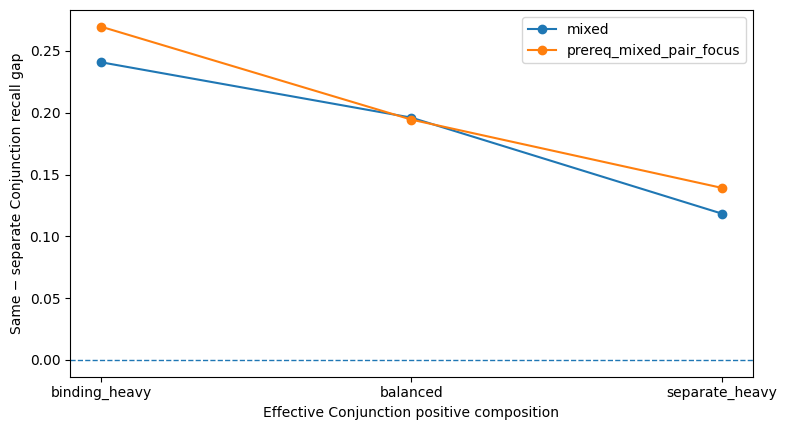

In [2]:
def paired_ci(v,alpha=.05):
    a = np.asarray(v,dtype=float)
    n = len(a)
    mean = float(a.mean())
    half = float(student_t.ppf(1-alpha/2,n-1)*a.std(ddof=1)/np.sqrt(n))
    return dict(mean=mean,low=mean-half,high=mean+half,n=n)

dose=frozen[frozen.kind=="spatial_3x3"]
wide=dose.pivot_table(index=["seed","schedule"],columns="composition",values="conj_recall_gap")
means=wide.groupby(level="seed").mean()
contrast=means.binding_heavy-means.separate_heavy
print("Binding-heavy − separate-heavy recall gap:",paired_ci(contrast))
display(dose.groupby(["schedule","composition"])[["conj_recall_gap","conjunction_leak_rate",
     "conj_directional_logit_shift","binding_auc"]].agg(["mean","std"]).round(3))

plt.figure(figsize=(8,4.4))
for schedule, part in dose[dose.composition.isin(("binding_heavy","balanced","separate_heavy"))].groupby("schedule"):
    vals = part.groupby("composition").conj_recall_gap.mean().reindex(["binding_heavy","balanced","separate_heavy"])
    plt.plot(vals.index, vals.values, marker="o", label=schedule)
plt.axhline(0,linestyle="--",linewidth=1)
plt.ylabel("Same − separate Conjunction recall gap")
plt.xlabel("Effective Conjunction positive composition")
plt.legend()
plt.tight_layout()
plt.savefig(ANALYSIS/"incentive_dose_response.png",dpi=180)
plt.show()

## 2. Does neighborhood mixing help Binding?

The 3×3 reader combines neighboring evidence before pooling; the 1×1 readers process each location independently. Comparing Binding discrimination and unwanted Conjunction changes shows both the potential gain and its cost.

In [3]:
kern = frozen[frozen.composition=="canonical"].copy()
show = ["binding_auc","strict_swap_correct_direction","conjunction_leak_rate","conj_recall_gap"]
display(kern.groupby(["schedule","kind"])[show].mean().round(3))
for outcome in show:
    wide = kern.pivot(index=["seed","schedule"],columns="kind",values=outcome)
    for control in ("spatial_1x1","spatial_1x1_wide"):
        paired=(wide.spatial_3x3-wide[control]).groupby(level="seed").mean()
        print(outcome,"3x3 −",control,paired_ci(paired))

binding_auc  \
schedule                kind                            
mixed                   spatial_1x1             0.656   
                        spatial_1x1_wide        0.683   
                        spatial_3x3             0.784   
prereq_mixed_pair_focus spatial_1x1             0.680   
                        spatial_1x1_wide        0.704   
                        spatial_3x3             0.796   

                                          strict_swap_correct_direction  \
schedule                kind                                              
mixed                   spatial_1x1                               0.661   
                        spatial_1x1_wide                          0.695   
                        spatial_3x3                               0.782   
prereq_mixed_pair_focus spatial_1x1                               0.696   
                        spatial_1x1_wide                          0.722   
                        spatial_3x3                               0.802   

                                          conjunction_leak_rate  \
schedule                kind                                      
mixed                   spatial_1x1                       0.204   
                        spatial_1x1_wide                  0.230   
                        spatial_3x3                       0.379   
prereq_mixed_pair_focus spatial_1x1                       0.212   
                        spatial_1x1_wide                  0.242   
                        spatial_3x3                       0.371   

                                          conj_recall_gap  
schedule                kind                               
mixed                   spatial_1x1                 0.011  
                        spatial_1x1_wide            0.020  
                        spatial_3x3                 0.198  
prereq_mixed_pair_focus spatial_1x1                 0.041  
                        spatial_1x1_wide            0.070  
                        spatial_3x3                 0.206

binding_auc 3x3 − spatial_1x1 {'mean': 0.12242240000000004, 'low': 0.031055915750655777, 'high': 0.2137888842493443, 'n': 5}
binding_auc 3x3 − spatial_1x1_wide {'mean': 0.09707780000000002, 'low': 0.027927083936551897, 'high': 0.16622851606344813, 'n': 5}
strict_swap_correct_direction 3x3 − spatial_1x1 {'mean': 0.11400000000000002, 'low': 0.03861299639858454, 'high': 0.1893870036014155, 'n': 5}
strict_swap_correct_direction 3x3 − spatial_1x1_wide {'mean': 0.0835, 'low': 0.02399842671099671, 'high': 0.14300157328900331, 'n': 5}
conjunction_leak_rate 3x3 − spatial_1x1 {'mean': 0.16699999999999998, 'low': 0.06021283555726886, 'high': 0.2737871644427311, 'n': 5}
conjunction_leak_rate 3x3 − spatial_1x1_wide {'mean': 0.13875, 'low': 0.04567695051374343, 'high': 0.2318230494862566, 'n': 5}
conj_recall_gap 3x3 − spatial_1x1 {'mean': 0.17639999999999995, 'low': 0.06275687638392673, 'high': 0.29004312361607315, 'n': 5}
conj_recall_gap 3x3 − spatial_1x1_wide {'mean': 0.1576, 'low': 0.064030916450

## 3. Does the Conv Stem improve prerequisite recognition?

Shape-only training measures what the stem can learn without competing questions. Mixed training shows whether that improvement persists and helps other tasks. We compare both the mean performance and differences within matched seeds.

shape_balanced_accuracy        shape_recolor_both_correct         \
                             mean    std                       mean    std   
stem                                                                         
conv_stem                   0.747  0.012                      0.664  0.018   
patchify                    0.673  0.007                      0.583  0.004   
pointwise                   0.669  0.025                      0.569  0.036   

          shape_recolor_both_correct_single_instance         \
                                                mean    std   
stem                                                          
conv_stem                                      0.547  0.066   
patchify                                       0.450  0.094   
pointwise                                      0.405  0.040   

          color_balanced_accuracy        conjunction_four_stratum_balanced  \
                             mean    std                              mean   
stem                                                                         
conv_stem                   0.990  0.012                             0.782   
patchify                    0.995  0.002                             0.750   
pointwise                   0.995  0.005                             0.736   

                  ... binding_auc_far        operator_three_case_joint         \
             std  ...            mean    std                      mean    std   
stem              ...                                                           
conv_stem  0.016  ...           0.706  0.139                     0.576  0.028   
patchify   0.009  ...           0.639  0.023                     0.532  0.012   
pointwise  0.006  ...           0.667  0.065                     0.525  0.025   

          swap_eight_correct        swap_eight_correct_heldout_created         \
                        mean    std                               mean    std   
stem                                                                            
conv_stem              0.173  0.066                              0.113  0.046   
patchify               0.116  0.009                              0.050  0.020   
pointwise              0.120  0.045                              0.063  0.029   

          repaired_ood_binding_auc         
                              mean    std  
stem                                       
conv_stem                    0.522  0.186  
patchify                     0.535  0.081  
pointwise                    0.563  0.192  

[3 rows x 24 columns]

shape_balanced_accuracy conv_stem − patchify {'mean': 0.07333333333333336, 'low': 0.04454161641747413, 'high': 0.10212505024919259, 'n': 3}
shape_balanced_accuracy pointwise − patchify {'mean': -0.0040000000000000036, 'low': -0.05000687425409883, 'high': 0.042006874254098825, 'n': 3}
shape_balanced_accuracy conv_stem − pointwise {'mean': 0.07733333333333337, 'low': 0.01388642661984589, 'high': 0.14078024004682083, 'n': 3}
shape_recolor_both_correct conv_stem − patchify {'mean': 0.08133333333333341, 'low': 0.031074289271876047, 'high': 0.13159237739479077, 'n': 3}
shape_recolor_both_correct pointwise − patchify {'mean': -0.013999999999999976, 'low': -0.09208257737094021, 'high': 0.06408257737094027, 'n': 3}
shape_recolor_both_correct conv_stem − pointwise {'mean': 0.09533333333333338, 'low': -0.018972997733398445, 'high': 0.2096396644000652, 'n': 3}
shape_recolor_both_correct_single_instance conv_stem − patchify {'mean': 0.09708737864077671, 'low': -0.28879809114568233, 'high': 0.482972

shape_balanced_accuracy        shape_recolor_both_correct       
                             mean    std                       mean    std
stem                                                                      
conv_stem                   0.720  0.020                      0.662  0.033
patchify                    0.636  0.040                      0.546  0.049
pointwise                   0.613  0.034                      0.517  0.048

Shape-only mechanism check, Shape BA conv_stem − patchify {'mean': 0.08433333333333333, 'low': -0.04768481702029022, 'high': 0.2163514836869569, 'n': 3}
Shape-only mechanism check, Shape BA pointwise − patchify {'mean': -0.022666666666666613, 'low': -0.1893879055955188, 'high': 0.14405457226218557, 'n': 3}
Shape-only mechanism check, Shape BA conv_stem − pointwise {'mean': 0.10699999999999994, 'low': 0.07091581543018631, 'high': 0.1430841845698136, 'n': 3}


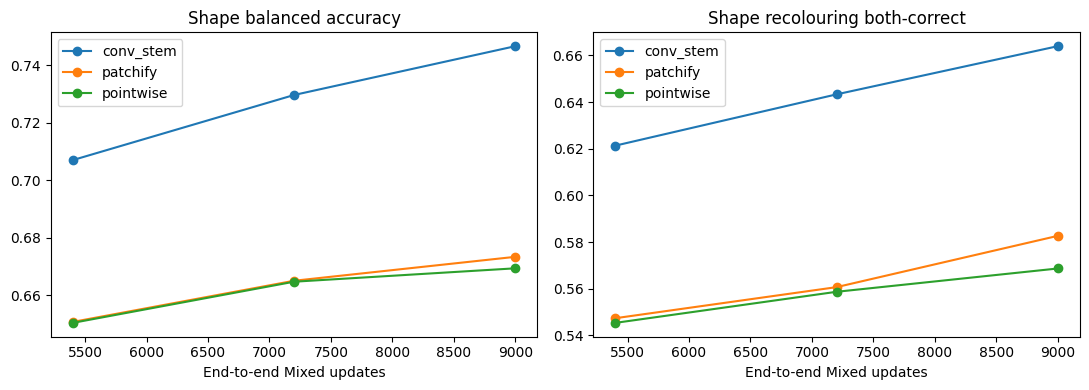

In [ ]:
final=stems[(stems["mode"]=="mixed") & (stems.step==9000)].copy()
cols=["shape_balanced_accuracy","shape_recolor_both_correct","shape_recolor_both_correct_single_instance",
      "color_balanced_accuracy","conjunction_four_stratum_balanced","binding_auc","binding_auc_close","binding_auc_far",
      "operator_three_case_joint","swap_eight_correct","swap_eight_correct_heldout_created","repaired_ood_binding_auc"]
display(final.groupby("stem")[cols].agg(["mean","std"]).round(3))
CONTRASTS=(("conv_stem","patchify"), ("pointwise","patchify"), ("conv_stem","pointwise"))
for metric in cols:
    wide = final.pivot(index="seed",columns="stem",values=metric)
    for a,b in CONTRASTS:print(metric,a,"−",b,paired_ci(wide[a]-wide[b]))
shape_only=stems[(stems["mode"]=="shape_only") & (stems.step==2250)]
display(shape_only.groupby("stem")[["shape_balanced_accuracy","shape_recolor_both_correct"]].agg(["mean","std"]).round(3))
wide = shape_only.pivot(index="seed",columns="stem",values="shape_balanced_accuracy")
for a,b in CONTRASTS:print("Shape-only mechanism check, Shape BA",a,"−",b,paired_ci(wide[a]-wide[b]))

fig, axs = plt.subplots(1,2,figsize=(11,4))
for stem,part in stems[stems["mode"]=="mixed"].groupby("stem"):
    curve=part.groupby("step")[["shape_balanced_accuracy", "shape_recolor_both_correct"]].mean().sort_index()
    axs[0].plot(curve.index, curve.shape_balanced_accuracy, marker="o", label=stem)
    axs[1].plot(curve.index, curve.shape_recolor_both_correct, marker="o", label=stem)
for ax, title in zip(axs, ("Shape balanced accuracy", "Shape recolouring both-correct")):
    ax.set_title(title)
    ax.set_xlabel("End-to-end Mixed updates")
    ax.legend()
fig.tight_layout()
fig.savefig(ANALYSIS/"stem_shape_learning.png",dpi=180)
plt.show()

## 4. Which Conjunction cases improve?

Overall accuracy can hide a shortcut. Each row of the heatmap is a model and each column is one logical case: bound positive, separate-object positive, Shape missing, or Color missing. The difference panel shows where Conv Stem fixes errors and where it introduces new ones.

,Same-object Yes,Separate-object Yes,Shape missing No,Color missing No
stem,,,,
patchify,85.7,83.5,30.9,100.0
pointwise,77.2,81.1,36.3,100.0
conv_stem,83.9,84.4,44.5,100.0


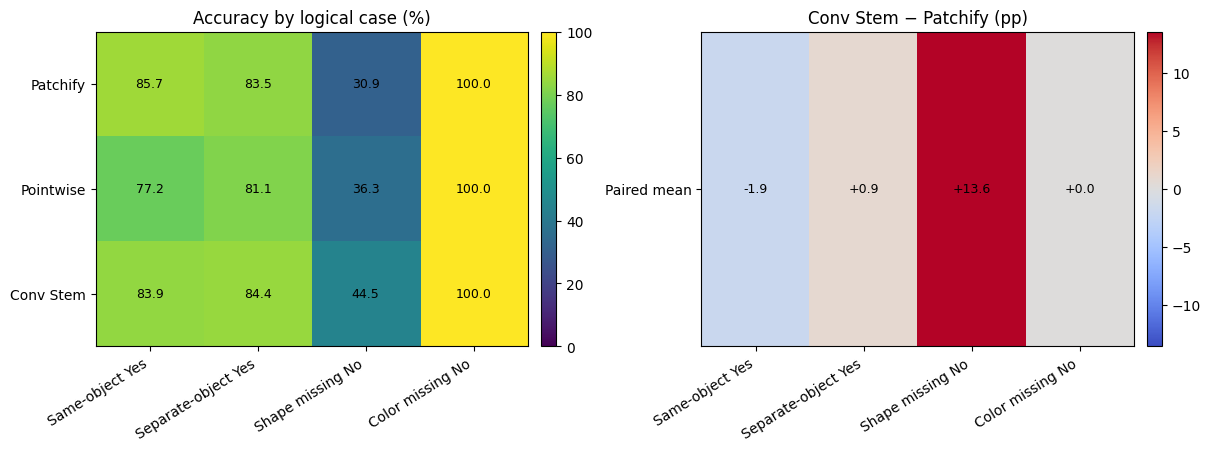

Each stratum contains 250 distinct selection questions per seed; uncertainty is across seeds, not question rows.


In [ ]:
CASE_ORDER=("bound_positive","separate_positive","shape_missing","color_missing")
CASE_LABELS=("Same-object Yes","Separate-object Yes","Shape missing No","Color missing No")
STEM_ORDER=("patchify","pointwise","conv_stem")
case_columns=[f"conjunction_{case}_correct" for case in CASE_ORDER]
case_means=final.groupby("stem")[case_columns].mean().reindex(STEM_ORDER)
case_diffs=(final[final.stem=="conv_stem"].set_index("seed")[case_columns]-
            final[final.stem=="patchify"].set_index("seed")[case_columns])
case_effect=(case_diffs.mean()*100).to_numpy()
display((case_means*100).round(1).rename(columns=dict(zip(case_columns,CASE_LABELS))))
case_means.to_csv(ANALYSIS/"conjunction_stratum_accuracy.csv")
case_diffs.to_csv(ANALYSIS/"conjunction_stratum_paired_differences.csv")
fig,axs=plt.subplots(1,2,figsize=(12,4.4),layout="constrained")
absolute=case_means.to_numpy()*100
scale=max(5,float(np.abs(case_effect).max()))
images=(axs[0].imshow(absolute,aspect="auto", vmin=0,vmax=100),
        axs[1].imshow(case_effect[None,:],aspect="auto",vmin=-scale,vmax=scale,cmap="coolwarm"))
for ax,im,title,rows in zip(axs,images,("Accuracy by logical case (%)","Conv Stem − Patchify (pp)"),
                            (("Patchify","Pointwise","Conv Stem"),("Paired mean",))):
    ax.set_title(title)
    ax.set_xticks(range(4),CASE_LABELS,rotation=32,ha="right")
    ax.set_yticks(range(len(rows)),rows)
    values=absolute if len(rows)==3 else case_effect[None,:]
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j,i,f"{values[i,j]:+.1f}" if len(rows)==1 else f"{values[i,j]:.1f}", ha="center", va="center",fontsize=9)
    fig.colorbar(im,ax=ax,fraction=0.047,pad=0.03)
fig.savefig(ANALYSIS/"conjunction_four_stratum_heatmaps.png", dpi=180, bbox_inches="tight")
plt.show()
print("Each stratum contains 250 distinct selection questions per seed; uncertainty is across seeds, not question rows.")

## 5. Can the model handle both critical Conjunction cases?

The horizontal axis measures how often a model correctly answers **Yes** when Color and Shape appear on separate objects. The vertical axis measures how often it correctly answers **No** when Shape is absent. **Higher and farther right are better.** A Color-only shortcut succeeds only on the first case; a Binding-like shortcut succeeds only on the second. The diagonal connects these two reference rules; crossing it does not prove reasoning.

The left panel varies the frozen reader's Conjunction loss weights across five paired seeds. The right panel compares the three end-to-end stems across three seeds.

Each Conjunction case contains 250 selection questions; means are across paired seeds.


,group,condition,n_seeds,separate_yes,shape_missing_no,two_case_surplus
0,End-to-end stem,conv_stem,3,84.4,44.5,28.9
1,End-to-end stem,patchify,3,83.5,30.9,14.4
2,End-to-end stem,pointwise,3,81.1,36.3,17.3
3,Frozen readout,balanced,5,63.4,45.6,8.9
4,Frozen readout,binding_heavy,5,56.5,51.7,8.2
5,Frozen readout,canonical,5,64.6,43.4,8.0
6,Frozen readout,separate_heavy,5,68.9,42.1,11.0
7,Frozen readout,spatial_1x1,5,81.7,32.4,14.2
8,Frozen readout,spatial_1x1_wide,5,78.4,35.9,14.3


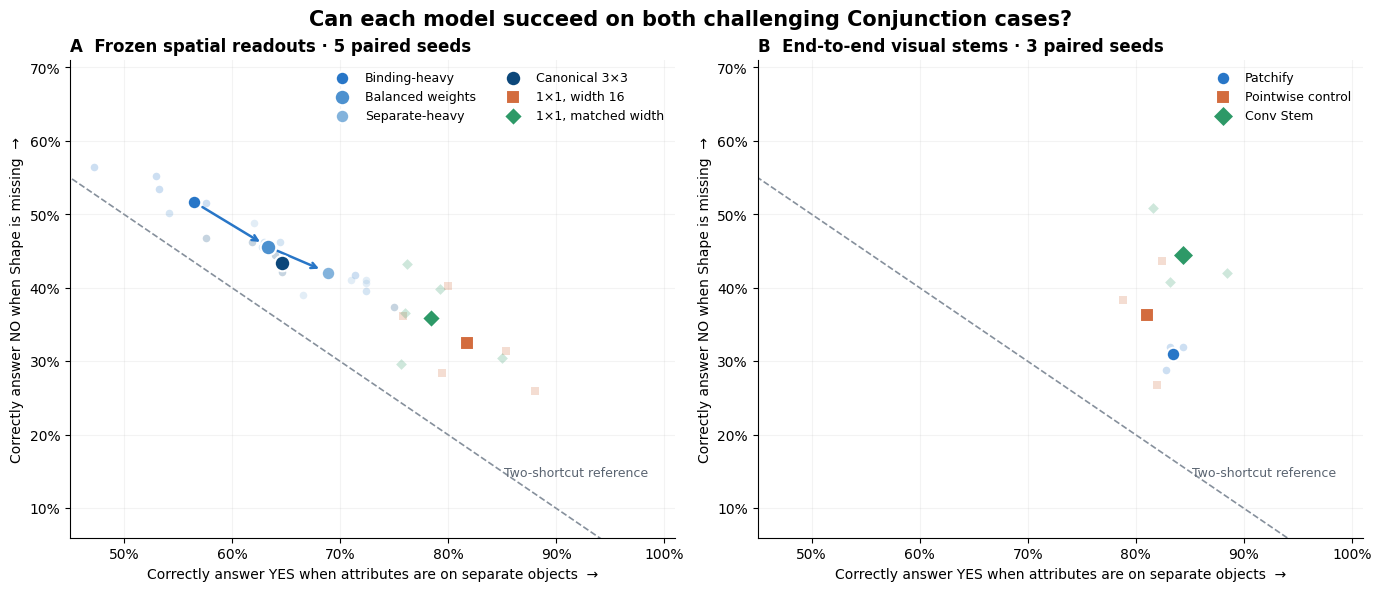

In [ ]:
# Conjunction succeeds only if BOTH types of questions are answered correctly.
# This is a descriptive two-case view, not the protocol's P2 (which averages four strata).
from matplotlib.ticker import PercentFormatter

frozen_cases=(frozen.copy().groupby(["seed","kind","composition"],as_index=False)
              [["conj_separate_recall","conj_shape_missing_specificity"]].mean())
frozen_cases["condition"]=np.where(frozen_cases.kind=="spatial_3x3",frozen_cases.composition,frozen_cases.kind)
stem_cases=final[["seed","stem","conjunction_separate_positive_correct","conjunction_shape_missing_correct"]].copy()
stem_cases=stem_cases.rename(columns={"conjunction_separate_positive_correct":"separate_yes",
                                      "conjunction_shape_missing_correct":"missing_no"})
frozen_cases=frozen_cases.rename(columns={"conj_separate_recall":"separate_yes",
                                         "conj_shape_missing_specificity":"missing_no"})
stem_cases["condition"]=stem_cases.stem

# A transparent, optional diagnostic: surplus over the line joining the two single-cue shortcuts.
# Surplus > 0 rules out *only* mixtures of those two idealized rules, not other shortcuts.
comparison=pd.concat([frozen_cases.assign(group="Frozen readout"),
                      stem_cases.assign(group="End-to-end stem")],ignore_index=True)
comparison["two_case_surplus"]=comparison.separate_yes+comparison.missing_no-1
case_summary=(comparison.groupby(["group","condition"]).agg(
    n_seeds=("seed","nunique"),separate_yes=("separate_yes","mean"),
    shape_missing_no=("missing_no","mean"),two_case_surplus=("two_case_surplus","mean"))
    .reset_index())
case_summary.to_csv(ANALYSIS/"conjunction_two_case_success_summary.csv",index=False)
print("Each Conjunction case contains 250 selection questions; means are across paired seeds.")
display(case_summary.assign(**{k:lambda x,col=k:(100*x[col]).round(1)
                             for k in ("separate_yes","shape_missing_no","two_case_surplus")}))

colors={"binding_heavy":"#2876C7","balanced":"#4D91CF","separate_heavy":"#83B3DC",
        "canonical":"#0C477A","spatial_1x1":"#D36C3E","spatial_1x1_wide":"#2D9967",
        "patchify":"#2876C7","pointwise":"#D36C3E","conv_stem":"#2D9967"}
markers={"binding_heavy":"o","balanced":"o","separate_heavy":"o","canonical":"o",
         "spatial_1x1":"s","spatial_1x1_wide":"D","patchify":"o","pointwise":"s","conv_stem":"D"}
labels={"binding_heavy":"Binding-heavy","balanced":"Balanced weights",
        "separate_heavy":"Separate-heavy","canonical":"Canonical 3×3",
        "spatial_1x1":"1×1, width 16","spatial_1x1_wide":"1×1, matched width",
        "patchify":"Patchify","pointwise":"Pointwise control","conv_stem":"Conv Stem"}
fig,axes=plt.subplots(1,2,figsize=(13.7,5.8),layout="constrained")
for ax,frame,conditions,title in [
    (axes[0],frozen_cases,("binding_heavy","balanced","separate_heavy","canonical","spatial_1x1","spatial_1x1_wide"),
     "A  Frozen spatial readouts · 5 paired seeds"),
    (axes[1],stem_cases,("patchify","pointwise","conv_stem"),
     "B  End-to-end visual stems · 3 paired seeds")]:
    x=np.linspace(.30,1,200)
    ax.plot(x,1-x,color="#86909C",linestyle="--",linewidth=1.2,zorder=0)
    ax.text(.985,.14,"Two-shortcut reference",ha="right",va="bottom",fontsize=9,color="#5A6471")
    for condition in conditions:
        values=frame[frame.condition==condition]
        color=colors[condition]
        mark=markers[condition]
        ax.scatter(values.separate_yes, values.missing_no, color=color, alpha=0.23, s=30, marker=mark, lw=0, zorder=2)
        ax.scatter(values.separate_yes.mean(),values.missing_no.mean(),s=125 if condition in ("conv_stem","canonical","balanced") else 95,
                   marker=mark,color=color,edgecolor="white",linewidth=1.5,zorder=4,label=labels[condition])
    if ax is axes[0]:
        means=frame.groupby("condition")[["separate_yes","missing_no"]].mean()
        for first,second in (("binding_heavy","balanced"),("balanced","separate_heavy")):
            p=means.loc[first]
            q=means.loc[second]
            ax.annotate("",xy=(q.separate_yes,q.missing_no),xytext=(p.separate_yes,p.missing_no),
                        arrowprops=dict(arrowstyle="->",color="#2876C7",lw=1.8,shrinkA=7,shrinkB=7))
    ax.set_title(title,loc="left",fontsize=12,fontweight="semibold")
    ax.set_xlim(.45,1.01)
    ax.set_ylim(.06,.71)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel("Correctly answer YES when attributes are on separate objects  →",fontsize=10)
    ax.set_ylabel("Correctly answer NO when Shape is missing  →",fontsize=10)
    ax.grid(alpha=.14)
    ax.spines[["top","right"]].set_visible(False)
    ax.legend(frameon=False,fontsize=9,loc="upper right",ncol=2 if ax is axes[0] else 1)
fig.suptitle("Can each model succeed on both challenging Conjunction cases?",fontsize=15,fontweight="semibold")
fig.savefig(ANALYSIS/"conjunction_two_case_success_scatter.png", dpi=210, bbox_inches="tight")
plt.show()

### How much does each critical answer improve?

The previous plot shows where each model ends up. Here, matched-seed differences show what the intervention changes: separate-object Yes recall and Shape-missing No specificity. A positive change fixes more answers; a negative change indicates a regression. Intervals are exploratory and use training seeds, not individual questions, as independent replications.

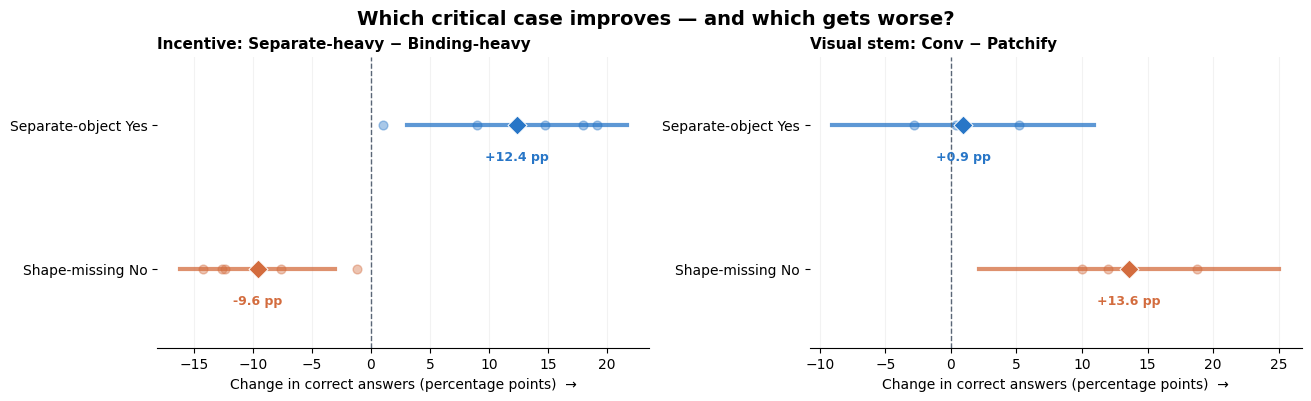

In [7]:
# Paired, seed-level changes in the same two correctly answered logical cases.
dose_wide=frozen_cases[frozen_cases.condition.isin(("binding_heavy","separate_heavy"))].pivot(
    index="seed",columns="condition",values=["separate_yes","missing_no"])
stem_wide=stem_cases.pivot(index="seed",columns="condition",values=["separate_yes","missing_no"])
changes=[]
for family,pivot,left,right in (("Incentive: Separate-heavy − Binding-heavy",dose_wide,"binding_heavy","separate_heavy"),
                               ("Visual stem: Conv − Patchify",stem_wide,"patchify","conv_stem")):
    for outcome in ("separate_yes","missing_no"):
        seed_effect=100*(pivot[(outcome,right)]-pivot[(outcome,left)])
        ci=paired_ci(seed_effect)
        for seed,effect in seed_effect.items():
            changes.append(dict(comparison=family,case=outcome,seed=int(seed),change_pp=float(effect),
                                mean_pp=ci["mean"],ci_low=ci["low"],ci_high=ci["high"],n_seeds=ci["n"]))
paired_cases=pd.DataFrame(changes)
paired_cases.to_csv(ANALYSIS/"conjunction_two_case_paired_shifts.csv",index=False)
fig,axes=plt.subplots(1,2,figsize=(13,3.9),layout="constrained")
for ax,(family,part) in zip(axes,paired_cases.groupby("comparison",sort=False)):
    for j,(outcome,caption,col) in enumerate((
            ("separate_yes","Separate-object Yes","#2876C7"),
            ("missing_no","Shape-missing No","#D36C3E"))):
        subset=part[part.case==outcome].sort_values("seed")
        y=j
        ax.scatter(subset.change_pp,np.full(len(subset),y),s=40,alpha=.4,color=col,zorder=3)
        mean=subset.mean_pp.iloc[0]
        lo=subset.ci_low.iloc[0]
        hi=subset.ci_high.iloc[0]
        ax.plot([lo,hi],[y,y],color=col,lw=3,alpha=.75,zorder=2)
        ax.scatter(mean,y,marker="D",s=94,color=col,edgecolor="white",linewidth=.7,zorder=4)
        ax.text(mean,y+.25,f"{mean:+.1f} pp",ha="center",fontsize=9,color=col,fontweight="semibold")
    ax.set_yticks([0,1],["Separate-object Yes","Shape-missing No"])
    ax.set_ylim(1.55,-.47)
    ax.axvline(0,color="#596576",lw=1,linestyle="--")
    ax.set_xlabel("Change in correct answers (percentage points)  →")
    ax.set_title(family,loc="left",fontsize=11,fontweight="semibold")
    ax.spines[["top","right","left"]].set_visible(False)
    ax.grid(axis="x",alpha=.16)
fig.suptitle("Which critical case improves — and which gets worse?", fontsize=14, fontweight="semibold")
fig.savefig(ANALYSIS/"conjunction_two_case_paired_shifts.png", dpi=210, bbox_inches="tight")
plt.show()

## 6. Are improvements consistent across seeds?

The effect plots show Conv Stem minus Patchify on the five planned outcomes and the main safety measures. Zero means no change. Intervals are based on three matched seeds and can be wide; they are not confirmation results.

,family,metric,comparison,mean_pp,low_pp,high_pp,n_seeds,seed_values_pp
0,Primary,P1 Shape BA,conv_stem − patchify,7.33,4.45,10.21,3,8.100;6.000;7.900
1,Primary,P1 Shape BA,conv_stem − pointwise,7.73,1.39,14.08,3,10.600;5.700;6.900
2,Primary,P2 Conjunction (4 strata),conv_stem − patchify,3.17,1.00,5.34,3,2.200;3.900;3.400
3,Primary,P2 Conjunction (4 strata),conv_stem − pointwise,4.57,0.34,8.79,3,2.900;4.500;6.300
4,Primary,P3 Binding AUC,conv_stem − patchify,7.30,-30.08,44.69,3,13.584;18.196;-9.871
5,Primary,P3 Binding AUC,conv_stem − pointwise,4.92,-12.77,22.62,3,9.792;8.229;-3.251
6,Primary,P4 Operator joint (3 cases),conv_stem − patchify,4.49,-5.42,14.39,3,8.800;3.733;0.933
7,Primary,P4 Operator joint (3 cases),conv_stem − pointwise,5.11,-1.70,11.92,3,7.733;2.267;5.333
8,Primary,P5 Eight-answer joint,conv_stem − patchify,5.67,-8.50,19.83,3,10.750;6.750;-0.500
9,Primary,P5 Eight-answer joint,conv_stem − pointwise,5.25,-1.32,11.82,3,8.250;4.250;3.250


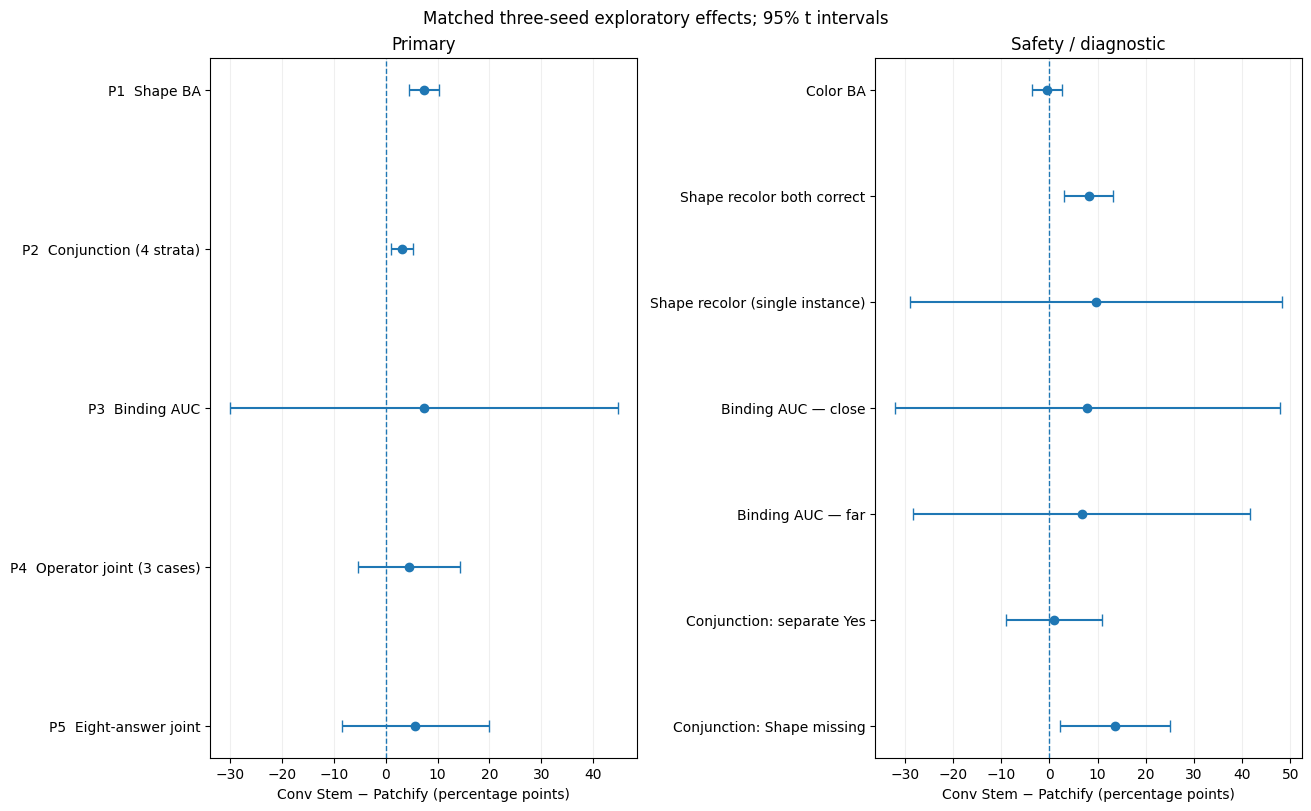

In [ ]:
PRIMARY_METRICS={
    "P1  Shape BA":"shape_balanced_accuracy",
    "P2  Conjunction (4 strata)":"conjunction_four_stratum_balanced",
    "P3  Binding AUC":"binding_auc",
    "P4  Operator joint (3 cases)":"operator_three_case_joint",
    "P5  Eight-answer joint":"swap_eight_correct",
}
SAFETY_METRICS={
    "Color BA":"color_balanced_accuracy",
    "Shape recolor both correct":"shape_recolor_both_correct",
    "Shape recolor (single instance)":"shape_recolor_both_correct_single_instance",
    "Binding AUC — close":"binding_auc_close",
    "Binding AUC — far":"binding_auc_far",
    "Conjunction: separate Yes":"conjunction_separate_positive_correct",
    "Conjunction: Shape missing":"conjunction_shape_missing_correct",
}
effects=[]
for family, metrics in (("Primary",PRIMARY_METRICS), ("Safety / diagnostic",SAFETY_METRICS)):
    for label,col in metrics.items():
        wide=final.pivot(index="seed",columns="stem",values=col)
        for control in ("patchify","pointwise"):
            paired=100*(wide["conv_stem"] - wide[control])
            ci=paired_ci(paired)
            effects.append(dict(family=family,metric=label,comparison=f"conv_stem − {control}",
                                mean_pp=ci["mean"],low_pp=ci["low"],high_pp=ci["high"],n_seeds=ci["n"],
                                seed_values_pp=";".join(f"{v:.3f}" for v in paired)))
effect_table=pd.DataFrame(effects)
effect_table.to_csv(ANALYSIS/"paired_effects_stem_selection.csv",index=False)
display(effect_table.round(2))
fig, axes = plt.subplots(1,2,figsize=(13,8),layout="constrained")
for ax,(family,metrics) in zip(axes,(("Primary",PRIMARY_METRICS),("Safety / diagnostic",SAFETY_METRICS))):
    subset=effect_table[(effect_table.family==family)&(effect_table.comparison=="conv_stem − patchify")]
    labels=list(metrics)
    sub=subset.set_index("metric").loc[labels]
    ys=np.arange(len(sub))[::-1]
    center=sub.mean_pp.to_numpy()
    low=sub.low_pp.to_numpy()
    high=sub.high_pp.to_numpy()
    ax.errorbar(center,ys,xerr=np.vstack([center-low,high-center]),fmt="o",capsize=4)
    ax.axvline(0,linestyle="--",linewidth=1)
    ax.set_yticks(ys,labels)
    ax.set_xlabel("Conv Stem − Patchify (percentage points)")
    ax.set_title(family)
    ax.grid(axis="x",alpha=.2)
fig.suptitle("Matched three-seed exploratory effects; 95% t intervals",fontsize=12)
fig.savefig(ANALYSIS/"stem_paired_effect_forest.png",dpi=180,bbox_inches="tight")
plt.show()

## 7. Which individual answers change?

We compare predictions for the same question under Patchify and Conv Stem. A repaired error is a question the baseline misses but Conv Stem gets right; a regression is the reverse. Separating the four Conjunction cases prevents a net accuracy gain from concealing a new shortcut.

,n,repaired,regressed,net_change
case,,,,
bound_positive,250.0,0.065,0.084,-0.019
separate_positive,250.0,0.095,0.085,0.009
shape_missing,250.0,0.199,0.063,0.136
color_missing,250.0,0.000,0.000,0.000


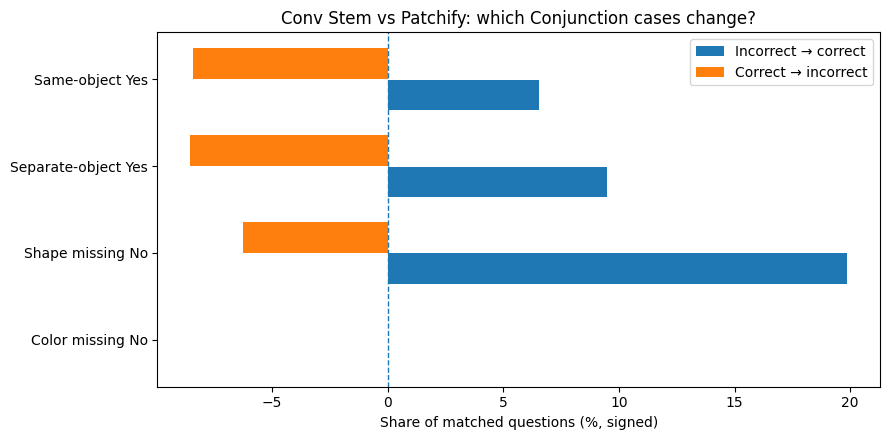

In [9]:
transitions=[]
for seed in sorted(final.seed.unique()):
    base=pd.read_csv(OUT_DIR/f"selection_stems/mixed/patchify_seed{seed}/selection_predictions_step9000.csv")
    new=pd.read_csv(OUT_DIR/f"selection_stems/mixed/conv_stem_seed{seed}/selection_predictions_step9000.csv")
    base=base.loc[base.group=="conjunction",["example_id","case","label","correct"]]
    new=new.loc[new.group=="conjunction",["example_id","correct"]]
    joined=base.merge(new,on="example_id",suffixes=("_patchify","_conv"),validate="one_to_one")
    for case,group in joined.groupby("case"):
        corrected=((group.correct_patchify==0)&(group.correct_conv==1)).mean()
        regressed=((group.correct_patchify==1)&(group.correct_conv==0)).mean()
        transitions.append(dict(seed=seed,case=case,n=len(group),repaired=corrected,regressed=regressed,
                                net_change=corrected-regressed))
transition_df=pd.DataFrame(transitions)
transition_df.to_csv(ANALYSIS/"conjunction_paired_error_transitions.csv",index=False)
display(transition_df.groupby("case")[["n","repaired","regressed","net_change"]].mean().reindex(CASE_ORDER).round(3))
means=transition_df.groupby("case")[["repaired","regressed"]].mean().reindex(CASE_ORDER)*100
fig,ax=plt.subplots(figsize=(9,4.5))
y=np.arange(4)
ax.barh(y+0.18,means.repaired,height=.35,label="Incorrect → correct")
ax.barh(y-0.18,-means.regressed,height=.35,label="Correct → incorrect")
ax.axvline(0,linestyle="--",linewidth=1)
ax.set_yticks(y,CASE_LABELS)
ax.invert_yaxis()
ax.set_xlabel("Share of matched questions (%, signed)")
ax.set_title("Conv Stem vs Patchify: which Conjunction cases change?")
ax.legend()
fig.tight_layout()
fig.savefig(ANALYSIS/"conjunction_paired_error_transitions.png", dpi=180, bbox_inches="tight")
plt.show()

## 8. Where is visual evidence located?

We compare signed attribute maps with rendered object regions. A map can encode a feature with either sign, so we inspect its full distribution rather than interpreting average ROC-AUC near 0.5 as absence of information. We also check whether the largest activations come from image borders rather than objects.

Signed AUC (not sign-invariant), interior-only AUC, and fraction of argmax tokens on borders:


patch_auc_signed              patch_auc_inner         \
                                mean    std count            mean    std   
stem      attribute                                                        
conv_stem color                0.757  0.202   720           0.762  0.209   
          shape                0.557  0.205   720           0.549  0.216   
patchify  color                0.872  0.180   720           0.869  0.179   
          shape                0.499  0.277   720           0.500  0.268   
pointwise color                0.707  0.320   720           0.715  0.311   
          shape                0.455  0.297   720           0.460  0.291   

                          absolute_alignment               
                    count               mean    std count  
stem      attribute                                        
conv_stem color       720              0.300  0.130   720  
          shape       720              0.169  0.128   720  
patchify  color       720              0.400  0.100   720  
          shape       720              0.243  0.133   720  
pointwise color       720              0.363  0.115   720  
          shape       720              0.263  0.146   720

argmax_on_border  argmin_on_border
stem      map                                            
conv_stem color                   0.193             0.190
          interaction             0.328             0.093
          joint                   0.468             0.180
          shape                   0.100             0.303
patchify  color                   0.008             0.018
          interaction             0.017             0.046
          joint                   0.032             0.004
          shape                   0.027             0.006
pointwise color                   0.142             0.024
          interaction             0.026             0.054
          joint                   0.050             0.023
          shape                   0.018             0.010

patch_auc_signed               \
                                    mean    std count   
stem      queried_shape                                 
conv_stem circle                   0.676  0.239   138   
          crescent                 0.532  0.116   231   
          square                   0.574  0.240   165   
          triangle                 0.484  0.190   186   
patchify  circle                   0.468  0.312   138   
          crescent                 0.672  0.187   231   
          square                   0.265  0.182   165   
          triangle                 0.515  0.259   186   
pointwise circle                   0.552  0.355   138   
          crescent                 0.449  0.247   231   
          square                   0.441  0.344   165   
          triangle                 0.405  0.244   186   

                        target_minus_other_signed               
                                             mean    std count  
stem      queried_shape                                         
conv_stem circle                            0.895  1.188   138  
          crescent                          0.311  0.471   231  
          square                            0.083  0.595   165  
          triangle                          0.082  0.645   186  
patchify  circle                            0.382  0.803   138  
          crescent                          0.112  0.428   231  
          square                           -0.025  0.520   165  
          triangle                          0.060  0.525   186  
pointwise circle                            0.157  0.765   138  
          crescent                          0.204  0.691   231  
          square                            0.006  0.681   165  
          triangle                          0.114  0.523   186

Uniform-token border reference: 0.234 ; object contrast retains its sign


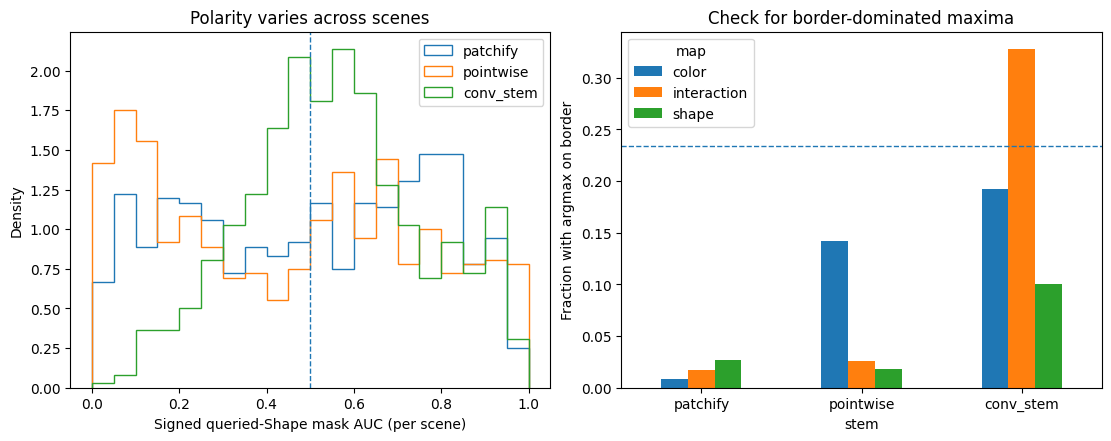

In [ ]:
import torch
from torch import nn
from sklearn.metrics import roc_auc_score
from src.medium_visual_world.learning import AttributeBindingViT, encode_query
from src.medium_visual_world.generate import read_jsonl, HOLDOUT
from src.medium_visual_world.representation_probing import image_tensor, foreground_concept_masks, query_tokens
from src.medium_visual_world.render import render
from src.medium_visual_world.world import from_dict, SHAPES

class PointwiseStemViT(AttributeBindingViT):
    def __init__(self,**kw):
        super().__init__(**kw)
        self.patch=nn.Sequential(nn.Conv2d(3,304,4,stride=4),nn.GELU(),
                                 nn.Conv2d(304,48,1),nn.GELU(),nn.Conv2d(48,48,1))

class ConvStemViT(AttributeBindingViT):
    def __init__(self,**kw):
        super().__init__(**kw)
        self.patch=nn.Sequential(nn.Conv2d(3,24,3,padding=1),nn.GELU(),
                                 nn.Conv2d(24,48,3,stride=2,padding=1),nn.GELU(),
                                 nn.Conv2d(48,48,3,stride=2,padding=1))

MODEL_TYPES={"patchify":AttributeBindingViT,"pointwise":PointwiseStemViT,"conv_stem":ConvStemViT}
DEVICE="cuda" if torch.cuda.is_available() else "cpu"

def load_selection_stem(stem,seed):
    path=OUT_DIR/f"selection_stems/mixed/{stem}_seed{seed}/model_step9000.pt"
    checkpoint=torch.load(path,map_location="cpu",weights_only=True)
    model=MODEL_TYPES[stem](dim=48,patch_size=4,depth=1)
    model.load_state_dict(checkpoint["model"])
    return model.to(DEVICE).eval()

@torch.inference_mode()
def score_maps(model,rows,images):
    queries=torch.tensor([encode_query(query_tokens("conjunction",r["color"],r["shape"]))
                          for r in rows],dtype=torch.long,device=images.device)
    e=model.emb(queries[:,1:4])
    joint_query=model.query(e.flatten(1))
    patches=model.patch(images).flatten(2).transpose(1,2)
    visual=model.score_norm(model.pre_norm(patches)+0.5*model.post_norm(model.encoder(patches+model.pos)))
    scale=visual.shape[-1]**.5
    s1=torch.einsum("bnd,bd->bn",visual,e[:,1])/scale
    s2=torch.einsum("bnd,bd->bn",visual,e[:,2])/scale
    sj=torch.einsum("bnd,bd->bn",visual,joint_query)/scale
    r=torch.tanh(s1)*torch.tanh(s2)
    return torch.stack((s1,s2,sj,r),dim=1).reshape(len(rows),4,16,16)

def maps_to_head_features(m):
    return torch.stack([f(m[:,k]) for k in range(4) for f in
                        (lambda x:x.amax(dim=(1,2)),lambda x:x.mean(dim=(1,2)))],dim=1)

conj_rows=list(read_jsonl(OUT_DIR/"selection/conjunction.jsonl"))
MODELS={(stem,int(seed)):load_selection_stem(stem,int(seed)) for seed in sorted(final.seed.unique()) for stem in STEM_ORDER}
BORDER=np.zeros((16,16),bool)
BORDER[[0,-1],:]=True
BORDER[:,[0,-1]]=True
SPATIAL_N_PER_CASE=80
sample_rows=[r for case in CASE_ORDER for r in [v for v in conj_rows if v["case"]==case][:SPATIAL_N_PER_CASE]]
spatial_masks=[foreground_concept_masks(r["scene"]) for r in sample_rows]
spatial_images=torch.stack([image_tensor(r["scene"]) for r in sample_rows])
spatial_alignment=[]
spatial_border=[]
spatial_maps={}
for (stem,seed),model in MODELS.items():
    chunks=[]
    for start in range(0,len(sample_rows),32):
        rows=sample_rows[start:start+32]
        chunks.append(score_maps(model,rows,spatial_images[start:start+32].to(DEVICE)).cpu().numpy())
    maps=np.concatenate(chunks)
    spatial_maps[(stem,seed)]=maps
    for i,row in enumerate(sample_rows):
        for kind,channel in (("color",0),("shape",1)):
            truth=spatial_masks[i][f"{kind}_{row[kind]}"].reshape(-1)
            score=maps[i,channel].reshape(-1)
            if 0<truth.sum()<len(truth):
                auc=roc_auc_score(truth,score)
                keep=~BORDER.reshape(-1)
                auc_inner=roc_auc_score(truth[keep],score[keep]) if 0<truth[keep].sum()<keep.sum() else np.nan
                rec=dict(seed=seed,stem=stem,case=row["case"],attribute=kind,
                         queried_shape=row["shape"],patch_auc_signed=auc,patch_auc_inner=auc_inner,
                         inverse_auc=1-auc,absolute_alignment=abs(auc-.5))
                if kind=="shape":
                    non_target=np.zeros(256,bool)
                    for other in SHAPES:
                        if other!=row["shape"]:non_target |= spatial_masks[i][f"shape_{other}"].reshape(-1)
                    non_target &= ~truth
                    rec["target_minus_other_signed"]=(score[truth].mean()-score[non_target].mean()
                                                      if non_target.any() else np.nan)
                spatial_alignment.append(rec)
        for channel,name in ((0,"color"),(1,"shape"),(2,"joint"),(3,"interaction")):
            score=maps[i,channel]
            largest=np.unravel_index(np.argmax(score),score.shape)
            smallest=np.unravel_index(np.argmin(score),score.shape)
            spatial_border.append(dict(seed=seed,stem=stem,case=row["case"],map=name,
                                       argmax_on_border=int(BORDER[largest]),argmin_on_border=int(BORDER[smallest]),
                                       border_max=float(score[BORDER].max()),
                                       interior_max=float(score[~BORDER].max())))
spatial_alignment=pd.DataFrame(spatial_alignment)
spatial_border=pd.DataFrame(spatial_border)
spatial_alignment.to_csv(ANALYSIS/"spatial_evidence_mask_alignment.csv",index=False)
spatial_border.to_csv(ANALYSIS/"spatial_evidence_border_diagnostics.csv",index=False)
print("Signed AUC (not sign-invariant), interior-only AUC, and fraction of argmax tokens on borders:")
display(spatial_alignment.groupby(["stem","attribute"])[["patch_auc_signed","patch_auc_inner","absolute_alignment"]].agg(["mean","std","count"]).round(3))
display(spatial_border.groupby(["stem","map"])[["argmax_on_border","argmin_on_border"]].mean().round(3))
display(spatial_alignment[spatial_alignment.attribute=="shape"].groupby(["stem","queried_shape"])[
    ["patch_auc_signed","target_minus_other_signed"]].agg(["mean","std","count"]).round(3))
print("Uniform-token border reference:",round(BORDER.mean(),3),"; object contrast retains its sign")
fig,axs=plt.subplots(1,2,figsize=(11,4.3),layout="constrained")
shape_align=spatial_alignment[spatial_alignment.attribute=="shape"]
for stem in STEM_ORDER:
    values=shape_align[shape_align.stem==stem]
    axs[0].hist(values.patch_auc_signed,bins=np.linspace(0,1,21),histtype="step",density=True,label=stem)
axs[0].set(xlabel="Signed queried-Shape mask AUC (per scene)",ylabel="Density",title="Polarity varies across scenes")
axs[0].axvline(.5,ls="--",lw=1);axs[0].legend()
border_summary=spatial_border[spatial_border["map"].isin(("color","shape","interaction"))].groupby(["stem","map"]).argmax_on_border.mean().unstack("map").reindex(STEM_ORDER)
border_summary.plot.bar(ax=axs[1],rot=0)
axs[1].axhline(BORDER.mean(),ls="--",lw=1,label="Uniform-token reference")
axs[1].set(ylabel="Fraction with argmax on border",title="Check for border-dominated maxima")
fig.savefig(ANALYSIS/"spatial_evidence_patch_auc.png", dpi=180, bbox_inches="tight")
plt.show()

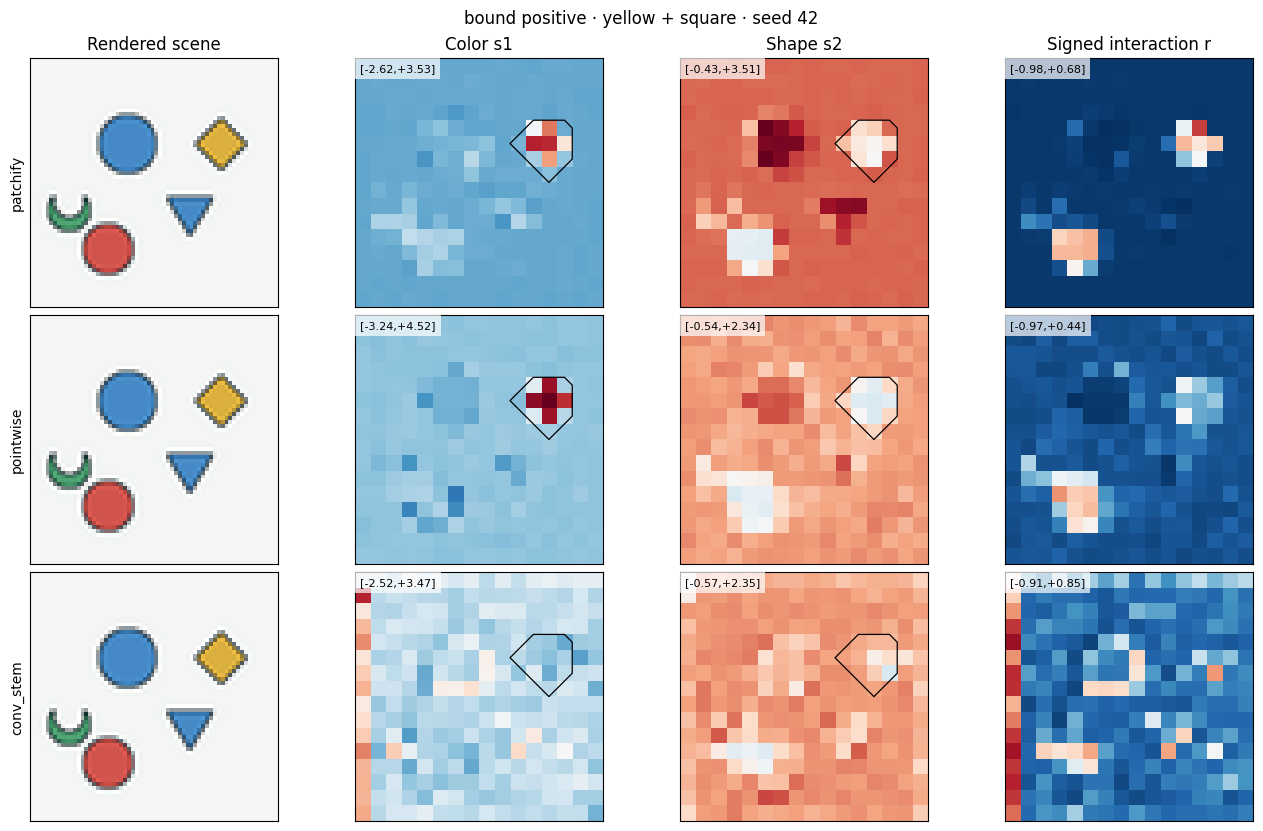

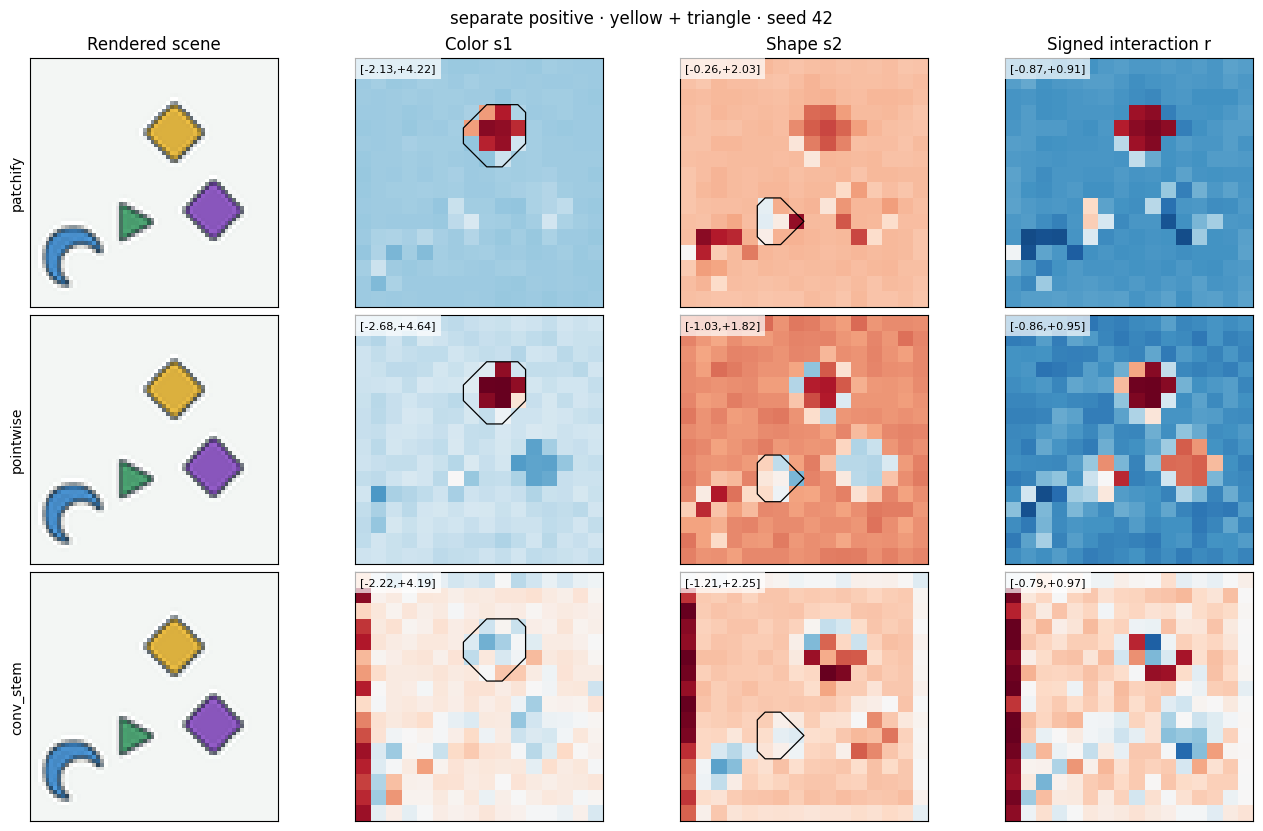

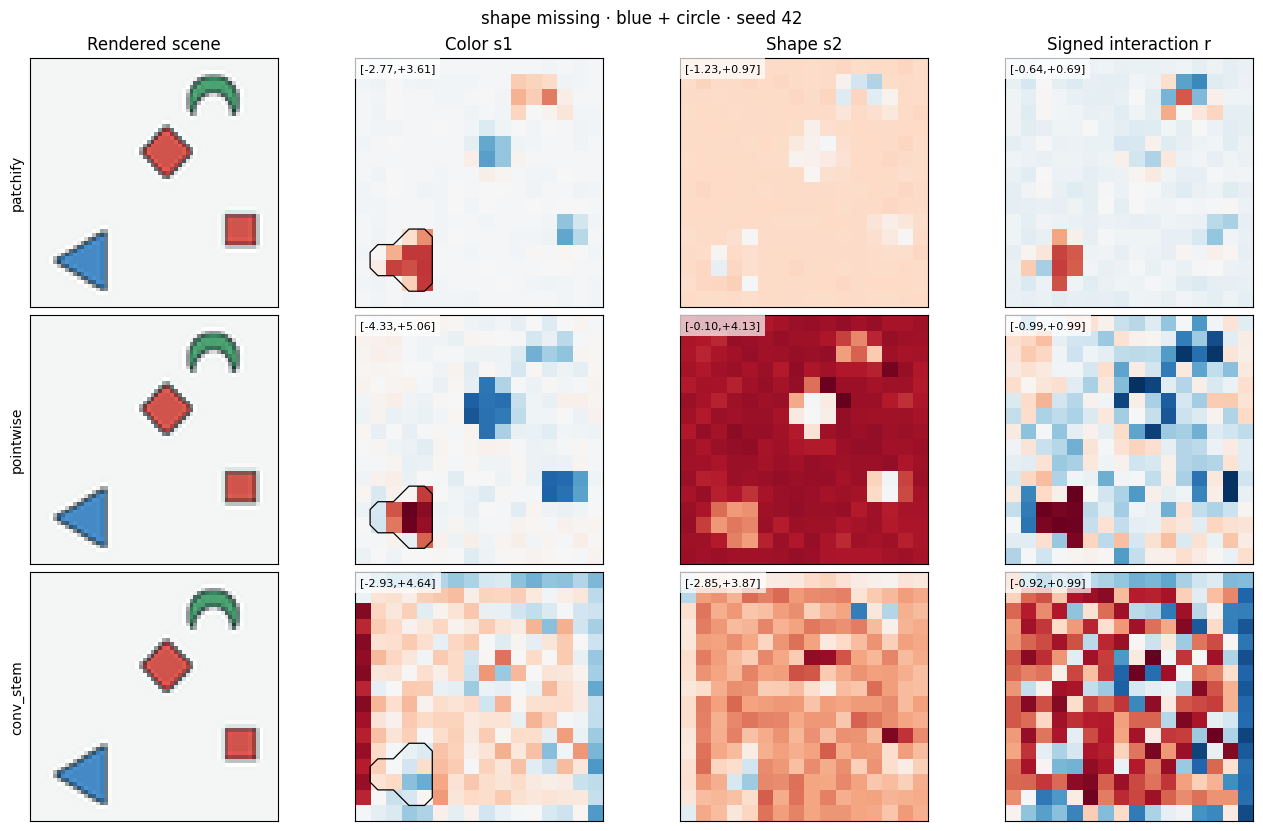

Every column uses a shared symmetric scale across stems, retaining polarity; model magnitudes are not calibrated.


In [ ]:
# One fixed scene per case, identical query and seed across stems; raw signs are preserved.
from matplotlib.colors import TwoSlopeNorm
for case in ("bound_positive","separate_positive","shape_missing"):
    index=next(i for i,r in enumerate(sample_rows) if r["case"]==case)
    row=sample_rows[index]
    original=np.asarray(render(from_dict(row["scene"])))
    fig,axs=plt.subplots(3,4,figsize=(13,8.2),layout="constrained")
    map_ids=(0,1,3)
    titles=("Color s1","Shape s2","Signed interaction r")
    limits=[max(1e-5,max(np.abs(spatial_maps[(stem,42)][index,k]).max() for stem in STEM_ORDER))
            for k in map_ids]
    for i,stem in enumerate(STEM_ORDER):
        axs[i,0].imshow(original)
        axs[i,0].set_ylabel(stem)
        for j,(channel,title,limit) in enumerate(zip(map_ids,titles,limits),start=1):
            data=spatial_maps[(stem,42)][index,channel]
            axs[i,j].imshow(data,cmap="RdBu_r",norm=TwoSlopeNorm(vmin=-limit,vcenter=0,vmax=limit), interpolation="nearest",origin="upper")
            kind="color" if channel==0 else "shape"
            if channel in (0,1):
                mask=spatial_masks[index][f"{kind}_{row[kind]}"].astype(float)
                if 0<mask.sum()<mask.size:axs[i,j].contour(mask,levels=[.5],colors="black",linewidths=.9)
            axs[i,j].text(.02,.98,f"[{data.min():+.2f},{data.max():+.2f}]",transform=axs[i,j].transAxes,
                          va="top",fontsize=8,color="black",bbox=dict(facecolor="white",alpha=.7,edgecolor="none"))
        for ax in axs[i]:ax.set_xticks([])
        ax.set_yticks([])
    for j,t in enumerate(("Rendered scene",*titles)):axs[0,j].set_title(t)
    fig.suptitle(f"{case.replace('_',' ')} · {row['color']} + {row['shape']} · seed 42",fontsize=12)
    fig.savefig(ANALYSIS/f"spatial_evidence_{case}.png",dpi=180,bbox_inches="tight")
    plt.show()
print("Every column uses a shared symmetric scale across stems, retaining polarity; model magnitudes are not calibrated.")

## 9. Is Shape evidence available but unused?

For the *same scenes*, we ask the model about Color, Shape and Conjunction. We compare standalone recognition with Conjunction decisions, then inspect the Shape score features reaching the Conjunction head. A disagreement shows inconsistent behavior across queries; it does not by itself prove a causal head defect.

shape_correct  conjunction_correct  \
stem      case                                                    
conv_stem bound_positive             0.637                0.839   
          color_missing              0.612                1.000   
          separate_positive          0.715                0.844   
          shape_missing              0.755                0.445   
patchify  bound_positive             0.545                0.857   
          color_missing              0.476                1.000   
          separate_positive          0.632                0.836   
          shape_missing              0.628                0.308   
pointwise bound_positive             0.533                0.772   
          color_missing              0.440                1.000   
          separate_positive          0.575                0.811   
          shape_missing              0.692                0.363   

                             both_prereq_correct  \
stem      case                                     
conv_stem bound_positive                   0.624   
          color_missing                    0.612   
          separate_positive                0.707   
          shape_missing                    0.743   
patchify  bound_positive                   0.540   
          color_missing                    0.476   
          separate_positive                0.627   
          shape_missing                    0.624   
pointwise bound_positive                   0.528   
          color_missing                    0.440   
          separate_positive                0.568   
          shape_missing                    0.685   

                             conj_error_given_prereq_correct  \
stem      case                                                 
conv_stem bound_positive                               0.036   
          color_missing                                0.000   
          separate_positive                            0.079   
          shape_missing                                0.458   
patchify  bound_positive                               0.059   
          color_missing                                0.000   
          separate_positive                            0.081   
          shape_missing                                0.573   
pointwise bound_positive                               0.097   
          color_missing                                0.000   
          separate_positive                            0.073   
          shape_missing                                0.519   

                             head_and_disagreement  
stem      case                                      
conv_stem bound_positive                     0.260  
          color_missing                      0.000  
          separate_positive                  0.249  
          shape_missing                      0.363  
patchify  bound_positive                     0.379  
          color_missing                      0.000  
          separate_positive                  0.311  
          shape_missing                      0.393  
pointwise bound_positive                     0.348  
          color_missing                      0.000  
          separate_positive                  0.325  
          shape_missing                      0.376

p_shape_auc        p_conjunction_auc        s2max_auc         \
                 mean    std              mean    std      mean    std   
stem                                                                     
conv_stem       0.826  0.011             0.724  0.032     0.717  0.071   
patchify        0.692  0.025             0.626  0.013     0.550  0.010   
pointwise       0.700  0.013             0.640  0.045     0.571  0.065   

          s2mean_auc         
                mean    std  
stem                         
conv_stem      0.566  0.061  
patchify       0.517  0.027  
pointwise      0.569  0.099

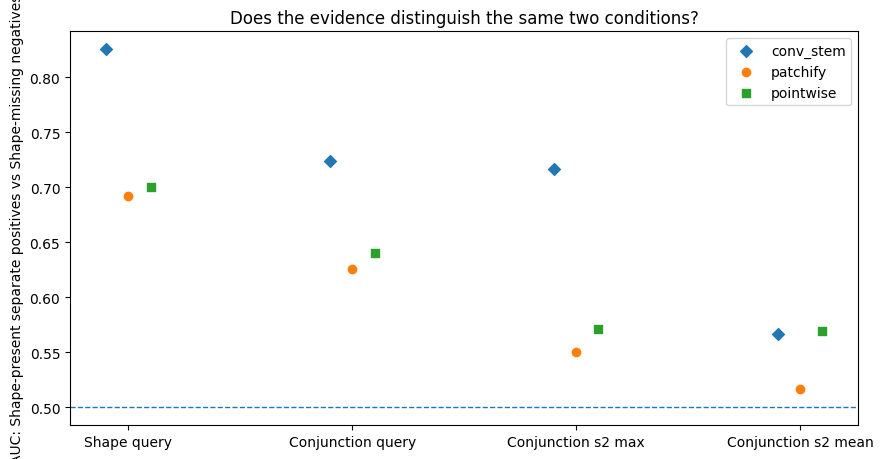

The two classes both contain queried Color; raw s2 polarity is not optimized or calibrated.


In [ ]:
from scipy.special import logit as probability_logit

@torch.inference_mode()
def cross_task_diagnostics(model,rows,batch_size=32):
    records=[]
    for start in range(0,len(rows),batch_size):
        block=rows[start:start+batch_size]
        images=torch.stack([image_tensor(row["scene"]) for row in block]).to(DEVICE)
        predictions={}
        logits={}
        for task in ("color","shape","conjunction"):
            q=torch.tensor([encode_query(query_tokens(task,r["color"],r["shape"])) for r in block],
                           dtype=torch.long,device=DEVICE)
            out=model(images,q)
            predictions[task]=out.softmax(1)[:,1].cpu().numpy()
            logits[task]=out
        maps=score_maps(model,block,images)
        head_features=maps_to_head_features(maps)
        if not torch.allclose(model.head(head_features),logits["conjunction"],atol=2e-5,rtol=2e-5):
            raise AssertionError("Conjunction score-map reconstruction differs from original forward path")
        feat=head_features.cpu().numpy()
        for i,row in enumerate(block):
            has_c=int(any(o["color"]==row["color"] for o in row["scene"]["objects"]))
            has_s=int(any(o["shape"]==row["shape"] for o in row["scene"]["objects"]))
            assert int(row["label"])==has_c*has_s
            probs={k:float(v[i]) for k,v in predictions.items()}
            answers={k:int(p>=.5) for k,p in probs.items()}
            records.append(dict(example_id=row["example_id"],case=row["case"],color=row["color"],
                                shape=row["shape"],true_color=has_c,true_shape=has_s,
                                true_conjunction=int(row["label"]),
                                **{f"p_{k}":v for k,v in probs.items()},
                                **{f"pred_{k}":v for k,v in answers.items()},
                                s2max=float(feat[i,2]),s2mean=float(feat[i,3]),
                                sjmax=float(feat[i,4]),sjmean=float(feat[i,5])))
    return pd.DataFrame(records)

cross_parts=[]
for (stem,seed),model in MODELS.items():
    part=cross_task_diagnostics(model,conj_rows)
    part.insert(0,"stem",stem)
    part.insert(0,"seed",seed)
    cross_parts.append(part)
cross_task=pd.concat(cross_parts,ignore_index=True)
cross_task["color_correct"]=(cross_task.pred_color==cross_task.true_color).astype(int)
cross_task["shape_correct"]=(cross_task.pred_shape==cross_task.true_shape).astype(int)
cross_task["conj_correct"]=(cross_task.pred_conjunction==cross_task.true_conjunction).astype(int)
cross_task["both_prereq_correct"]=(cross_task.color_correct & cross_task.shape_correct).astype(int)
cross_task["predicted_and"]=(cross_task.pred_color & cross_task.pred_shape).astype(int)
cross_task["and_head_disagree"]=(cross_task.predicted_and!=cross_task.pred_conjunction).astype(int)
cross_task.to_csv(ANALYSIS/"matched_scene_cross_task_predictions.csv",index=False)

behavior=(cross_task.groupby(["seed","stem","case"]).agg(
    color_correct=("color_correct","mean"),shape_correct=("shape_correct","mean"),
    conjunction_correct=("conj_correct","mean"),both_prereq_correct=("both_prereq_correct","mean"),
    head_and_disagreement=("and_head_disagree","mean")).reset_index())
conditional=[]
for (seed,stem,case),g in cross_task.groupby(["seed","stem","case"]):
    sufficient=g[g.both_prereq_correct==1]
    conditional.append(dict(seed=seed,stem=stem,case=case,n=len(g),n_prereq_correct=len(sufficient),
                            conj_error_given_prereq_correct=float((1-sufficient.conj_correct).mean()) if len(sufficient) else np.nan))
conditional=pd.DataFrame(conditional)
behavior=behavior.merge(conditional,on=["seed","stem","case"],validate="one_to_one")
behavior.to_csv(ANALYSIS/"matched_scene_cross_task_summary.csv",index=False)
display(behavior.groupby(["stem","case"])[["shape_correct","conjunction_correct",
      "both_prereq_correct","conj_error_given_prereq_correct","head_and_disagreement"]].mean().round(3))

availability=[]
for (seed,stem),g in cross_task.groupby(["seed","stem"]):
    test=g[g.case.isin(("separate_positive","shape_missing"))]
    y=(test.case=="separate_positive").astype(int)
    row=dict(seed=seed,stem=stem,n=len(test))
    for field in ("p_shape","p_conjunction","s2max","s2mean"):
        row[field+"_auc"]=roc_auc_score(y,test[field])
    availability.append(row)
availability = pd.DataFrame(availability)
availability.to_csv(ANALYSIS/"evidence_availability_vs_use_auc.csv",index=False)
display(availability.groupby("stem")[["p_shape_auc","p_conjunction_auc","s2max_auc","s2mean_auc"]].agg(["mean","std"]).round(3))
fig,ax = plt.subplots(figsize=(9,4.7))
auc_cols=("p_shape_auc","p_conjunction_auc","s2max_auc","s2mean_auc")
for j,(stem,g) in enumerate(availability.groupby("stem")):
    mean = g[list(auc_cols)].mean()
    ax.scatter(np.arange(4)+(j-1)*.1, mean, marker=("o","s","D")[STEM_ORDER.index(stem)], label=stem)
ax.set_xticks(range(4),("Shape query","Conjunction query","Conjunction s2 max","Conjunction s2 mean"))
ax.axhline(.5,ls="--",lw=1)
ax.set(ylabel="AUC: Shape-present separate positives vs Shape-missing negatives",
       title="Does the evidence distinguish the same two conditions?")
ax.legend()
fig.tight_layout()
fig.savefig(ANALYSIS/"evidence_availability_vs_use.png",dpi=180,bbox_inches="tight")
plt.show()
print("The two classes both contain queried Color; raw s2 polarity is not optimized or calibrated.")

## 10. Is the Shape improvement broad and color-stable?

We measure Shape accuracy by class rather than only reporting the pooled mean. Held-out-creating swaps test whether recognition survives when a queried-Shape object acquires a novel Color–Shape pairing. These are exploratory diagnostics on the selection set.

mean    std
stem      shape                 
conv_stem circle    0.794  0.021
          crescent  0.912  0.042
          square    0.677  0.047
          triangle  0.632  0.033
patchify  circle    0.767  0.013
          crescent  0.690  0.032
          square    0.648  0.018
          triangle  0.593  0.002
pointwise circle    0.731  0.039
          crescent  0.706  0.049
          square    0.665  0.056
          triangle  0.576  0.012

Held-out-creating swap pairs: 100 ; queried-Shape object held-out: 63


before_correct        after_correct        logit_change         \
                    mean    std          mean    std         mean    std   
stem                                                                       
conv_stem          0.667  0.042         0.519  0.024       -0.940  0.192   
patchify           0.471  0.048         0.434  0.075       -0.360  0.065   
pointwise          0.434  0.064         0.365  0.057       -0.386  0.066   

          answer_flip         
                 mean    std  
stem                          
conv_stem       0.296  0.033  
patchify        0.238  0.097  
pointwise       0.217  0.009

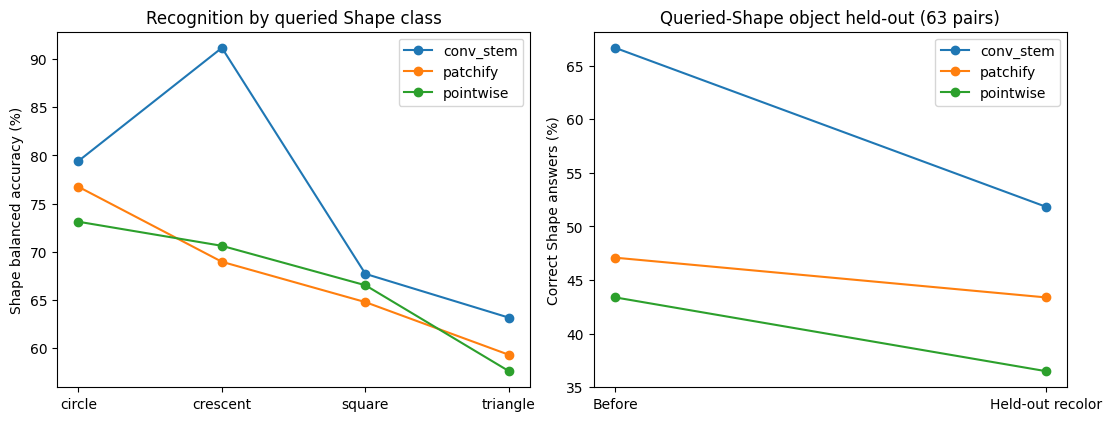

In [ ]:
# Shape BA by class: average recall on Shape-present and Shape-absent questions.
shape_class=[]
for seed in sorted(final.seed.unique()):
    for stem in STEM_ORDER:
        f=pd.read_csv(OUT_DIR/f"selection_stems/mixed/{stem}_seed{seed}/selection_predictions_step9000.csv")
        f=f[f.group=="recolor"]
        for shape,g in f.groupby("shape"):
            rates=g.groupby("label").correct.mean()
            shape_class.append(dict(seed=seed,stem=stem,shape=shape,n_rows=len(g),
                                    balanced_accuracy=float(rates.loc[[0,1]].mean()),
                                    positive_recall=float(rates.loc[1]),negative_specificity=float(rates.loc[0])))
shape_class=pd.DataFrame(shape_class)
shape_class.to_csv(ANALYSIS/"shape_class_breakdown.csv",index=False)
display(shape_class.groupby(["stem","shape"]).balanced_accuracy.agg(["mean","std"]).round(3))

swap_rows=[r for r in read_jsonl(OUT_DIR/"selection/swaps.jsonl")
           if r["task"]=="shape" and r["state"]=="after" and int(r["heldout_created"])==1]
heldout_shape_pairs={r["pair_id"] for r in swap_rows if any(
    (o["color"],o["shape"]) in HOLDOUT and o["shape"]==r["shape"] for o in r["scene"]["objects"])}
print("Held-out-creating swap pairs:",len(swap_rows),"; queried-Shape object held-out:",len(heldout_shape_pairs))

heldout=[]
for seed in sorted(final.seed.unique()):
    for stem in STEM_ORDER:
        f=pd.read_csv(OUT_DIR/f"selection_stems/mixed/{stem}_seed{seed}/selection_predictions_step9000.csv")
        f=f[(f.group=="swaps") & (f.task=="shape") & (f.heldout_created==1) & f.pair_id.isin(heldout_shape_pairs)]
        wide=f.pivot(index="pair_id",columns="state",values=["prob_yes","correct"])
        assert len(wide)==len(heldout_shape_pairs)
        before=wide["prob_yes"]["before"].clip(1e-7,1-1e-7)
        after=wide["prob_yes"]["after"].clip(1e-7,1-1e-7)
        heldout.append(dict(seed=seed,stem=stem,n_pairs=len(wide),
                            before_correct=float(wide["correct"]["before"].mean()),
                            after_correct=float(wide["correct"]["after"].mean()),
                            logit_change=float((probability_logit(after)-probability_logit(before)).mean()),
                            answer_flip=float(((after>=.5)!=(before>=.5)).mean())))
heldout=pd.DataFrame(heldout)
heldout.to_csv(ANALYSIS/"heldout_color_shape_retention.csv",index=False)
display(heldout.groupby("stem")[["before_correct","after_correct","logit_change","answer_flip"]].agg(["mean","std"]).round(3))

fig,axs=plt.subplots(1,2,figsize=(11,4.1),layout="constrained")
classes=sorted(shape_class["shape"].unique())
for stem,g in shape_class.groupby("stem"):
    axs[0].plot(classes,100*g.groupby("shape").balanced_accuracy.mean().reindex(classes),marker="o",label=stem)
axs[0].set(ylabel="Shape balanced accuracy (%)",title="Recognition by queried Shape class")
axs[0].legend()
for stem,g in heldout.groupby("stem"):
    axs[1].plot((0,1),100*g[["before_correct","after_correct"]].mean().to_numpy(),marker="o",label=stem)
axs[1].set(xticks=[0,1], xticklabels=["Before","Held-out recolor"], ylabel="Correct Shape answers (%)",
           title=f"Queried-Shape object held-out ({len(heldout_shape_pairs)} pairs)")
axs[1].legend()
fig.savefig(ANALYSIS/"shape_classes_and_heldout_color.png", dpi=180, bbox_inches="tight")
plt.show()

## 11. Are the operators responding selectively to association changes?

An ID-safe Color swap changes Binding truth but preserves Color, Shape and Conjunction truth. We compare signed logit changes on matched pairs, then inspect the operator tuples where Conjunction should answer Yes and Binding No. The differences are behavioral, not causal decomposition of the head.

operator_logit_gap        conjunction_correct         \
                                   mean    std                mean    std   
stem      case                                                              
conv_stem discordant              1.565  0.049               0.785  0.032   
          negative                1.459  0.100               0.719  0.026   
          positive                0.699  0.726               0.847  0.066   
patchify  discordant              1.035  0.162               0.775  0.022   
          negative                0.343  0.283               0.637  0.013   
          positive                0.691  0.298               0.828  0.014   
pointwise discordant              1.181  0.231               0.743  0.035   
          negative               -0.234  1.024               0.675  0.058   
          positive                0.754  0.174               0.792  0.069   

                     binding_correct        joint_correct         
                                mean    std          mean    std  
stem      case                                                    
conv_stem discordant           0.687  0.039         0.476  0.012  
          negative             0.879  0.038         0.688  0.038  
          positive             0.620  0.165         0.565  0.129  
patchify  discordant           0.539  0.068         0.345  0.064  
          negative             0.775  0.052         0.617  0.022  
          positive             0.700  0.128         0.632  0.106  
pointwise discordant           0.624  0.129         0.401  0.099  
          negative             0.812  0.097         0.635  0.058  
          positive             0.612  0.191         0.540  0.165

mean    std
stem      task                                              
conv_stem color                                 0.008  0.110
          conjunction                          -0.322  0.119
          conjunction_minus_attribute_controls -0.263  0.105
          pair                                 -1.171  0.906
          shape                                -0.126  0.081
patchify  color                                 0.008  0.071
          conjunction                          -0.345  0.192
          conjunction_minus_attribute_controls -0.324  0.172
          pair                                 -0.562  0.158
          shape                                -0.050  0.034
pointwise color                                 0.037  0.019
          conjunction                          -0.345  0.206
          conjunction_minus_attribute_controls -0.330  0.252
          pair                                 -0.659  0.413
          shape                                -0.067  0.088

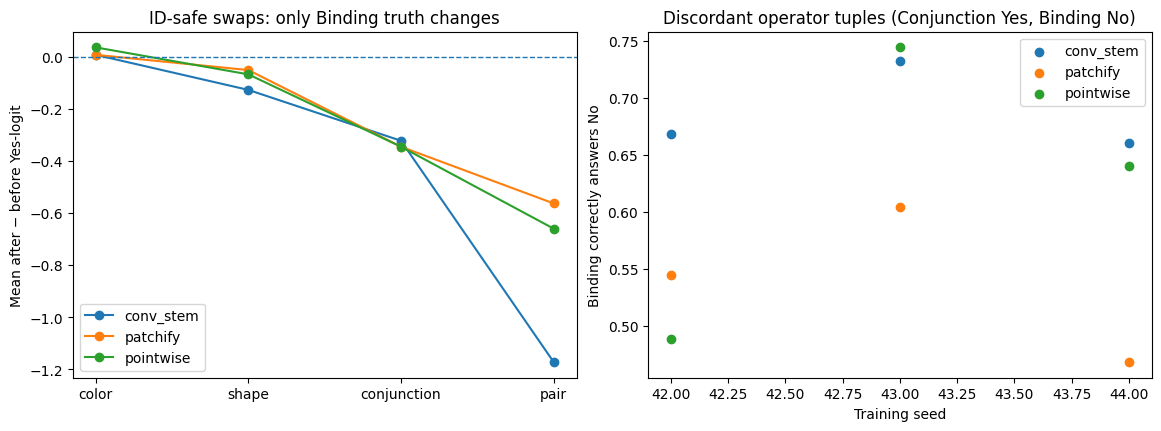

Net-of-controls is descriptive only: task logits pass through a shared nonlinear head.


In [ ]:
operator_summary=[]
swap_summary=[]
for seed in sorted(final.seed.unique()):
    for stem in STEM_ORDER:
        f=pd.read_csv(OUT_DIR/f"selection_stems/mixed/{stem}_seed{seed}/selection_predictions_step9000.csv")
        op=f[f.group=="operator"].copy()
        op["margin"]=probability_logit(op.prob_yes.clip(1e-7,1-1e-7))
        for case,g in op.groupby("case"):
            pivot=g.pivot(index="pair_id",columns="task",values=["margin","correct"])
            operator_summary.append(dict(seed=seed,stem=stem,case=case,n_tuples=len(pivot),
                                         operator_logit_gap=float((pivot["margin"]["conjunction"]-pivot["margin"]["pair"]).mean()),
                                         conjunction_correct=float(pivot["correct"]["conjunction"].mean()),
                                         binding_correct=float(pivot["correct"]["pair"].mean()),
                                         joint_correct=float(pivot["correct"].min(axis=1).mean())))
        sw=f[(f.group=="swaps") & (f.heldout_created==0)].copy()
        sw["margin"]=probability_logit(sw.prob_yes.clip(1e-7,1-1e-7))
        pivot=sw.pivot(index=["pair_id","task"],columns="state",values="margin")
        changes=(pivot["after"]-pivot["before"]).unstack("task")
        assert set(changes.columns)=={"color","shape","conjunction","pair"}
        for task in ("color","shape","conjunction","pair"):
            swap_summary.append(dict(seed=seed,stem=stem,task=task,n_pairs=len(changes),
                                     mean_logit_change=float(changes[task].mean()),
                                     median_abs_change=float(changes[task].abs().median())))
        swap_summary.append(dict(seed=seed,stem=stem,task="conjunction_minus_attribute_controls",
                                 n_pairs=len(changes),mean_logit_change=float((changes["conjunction"]-
                                 .5*(changes["color"]+changes["shape"])).mean()),median_abs_change=np.nan))
operator_summary=pd.DataFrame(operator_summary)
swap_summary=pd.DataFrame(swap_summary)
operator_summary.to_csv(ANALYSIS/"operator_routing_diagnostics.csv",index=False)
swap_summary.to_csv(ANALYSIS/"swap_logit_selectivity.csv",index=False)
display(operator_summary.groupby(["stem","case"])[["operator_logit_gap","conjunction_correct",
                                           "binding_correct","joint_correct"]].agg(["mean","std"]).round(3))
display(swap_summary.groupby(["stem","task"]).mean_logit_change.agg(["mean","std"]).round(3))
fig,axs=plt.subplots(1,2,figsize=(11.5,4.2),layout="constrained")
for stem,g in swap_summary[swap_summary.task.isin(("color","shape","conjunction","pair"))].groupby("stem"):
    order=("color","shape","conjunction","pair")
    axs[0].plot(order,g.groupby("task").mean_logit_change.mean().reindex(order),marker="o",label=stem)
axs[0].axhline(0,ls="--",lw=1)
axs[0].set(ylabel="Mean after − before Yes-logit",title="ID-safe swaps: only Binding truth changes")
axs[0].legend()
for stem,g in operator_summary[operator_summary.case=="discordant"].groupby("stem"):
    axs[1].scatter(g.seed,g.binding_correct,label=stem)
axs[1].set(xlabel="Training seed",ylabel="Binding correctly answers No",
           title="Discordant operator tuples (Conjunction Yes, Binding No)")
axs[1].legend()
fig.savefig(ANALYSIS/"operator_and_swap_selectivity.png",dpi=180,bbox_inches="tight")
plt.show()
print("Net-of-controls is descriptive only: task logits pass through a shared nonlinear head.")

## 12. Interpret the selection evidence

The selection gates identify promising interventions, not confirmed mechanisms. Read the signed-map, same-scene and swap diagnostics together before deciding whether the remaining bottleneck is visual recognition, task-specific use of evidence, or both. No confirmation data are used here.

In [15]:
decision=pd.DataFrame([dict(gate="G1",value=g1["G1"],evidence=g1["binding_heavy_minus_separate"]["mean"],
                             note="Frozen-readout incentive; does not identify encoder incentive"),
                       dict(gate="D1",value=d1["D1_selected"],evidence=d1["shape_gain"],
                            note="Mixed Shape balanced-accuracy gain; requires safety constraints")])
display(decision)
decision.to_csv(ANALYSIS/"selection_gate_summary.csv",index=False)
print("Provisional confirmation seed count:",d1["illustrative_confirmation_n"])
print("No confirmation split, confirmation labels or confirmation model scores were accessed.")

,gate,value,evidence,note
0,G1,True,0.126400,Frozen-readout incentive; does not identify en...
1,D1,True,0.073333,Mixed Shape balanced-accuracy gain; requires s...


Provisional confirmation seed count: 8
No confirmation split, confirmation labels or confirmation model scores were accessed.
